# Tema 5 · Matemáticas con código: pendientes, promedios y azar

La matemática mínima para entender cómo aprende un modelo, aprendida programando.

Este cuaderno es el tema 5 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/5-matematicas-con-codigo-pendientes-promedios-y-azar/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Imagina que estás en un cerro, de noche y con niebla, y quieres bajar al valle. No ves el camino ni el fondo; solo sientes con los pies hacia dónde se inclina el suelo. ¿Cómo eliges para dónde dar el próximo paso?

Esa es, casi palabra por palabra, la situación de un modelo de inteligencia artificial cuando aprende. El modelo no «ve» la mejor respuesta: solo puede medir, en el lugar donde está, hacia dónde baja su error, y dar un paso en esa dirección. Para eso necesita saber medir **pendientes**. Y como aprende de datos que traen ruido y azar, también necesita **promedios** para resumirlos y **probabilidades** para razonar con lo incierto.

En este tema no vas a memorizar fórmulas: vas a **calcular cada idea con código** y comprobarla con números y gráficos. Vas a:

- aproximar una **derivada** con la computadora y leerla como la pendiente de una curva;
- calcular el **gradiente** de una función de dos variables y ver que apunta cuesta arriba;
- calcular la **media**, la **varianza** y la **desviación estándar**, y **estandarizar** datos;
- **simular** el azar para estimar probabilidades, usar la **regla de Bayes** y entender la **distribución normal**;
- usar `log` y `exp`, y explicar por qué el logaritmo convierte productos en sumas.

Necesitas lo del tema 3 (arreglos de NumPy) y lo del tema 4 (gráficos con matplotlib). De matemática, basta con la del colegio: qué es una función y cómo se calcula la pendiente de una recta.

## Actividad: la pendiente

Antes de cualquier fórmula, juega. En el panel 1 hay una curva y un punto coral que puedes arrastrar. La línea gruesa es la **tangente**: la recta que «roza» la curva en ese punto y tiene su misma inclinación. La línea punteada es una **secante**: une tu punto con otro que está *h* más a la derecha. En el panel 2 hay un mapa de **curvas de nivel**, como el de un cerro visto desde arriba; al tocarlo aparece una flecha: el **gradiente** en ese lugar.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/5-matematicas-con-codigo-pendientes-promedios-y-azar/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Con *h* = 1, mueve el punto por toda la curva. ¿Dónde es positiva la pendiente de la tangente, dónde negativa y dónde vale cero?
2. Deja el punto quieto y achica *h* paso a paso. ¿Qué le pasa a la secante? ¿Y a la diferencia entre las dos pendientes?
3. En el mapa, toca puntos sobre una misma curva de nivel. ¿Qué ángulo forma cada flecha con la curva?
4. Toca un punto cerca del centro y otro lejos. ¿Cuál flecha es más larga? ¿Qué significa eso para el cerro?
5. Toca un punto como (2; 1). ¿La flecha apunta exactamente hacia afuera, lejos del centro?

Lo que acabas de ver es el corazón del tema: **la derivada es la pendiente de la tangente, y se puede aproximar con secantes cada vez más cortas**. Con dos variables, el **gradiente** junta las pendientes en una flecha que apunta cuesta arriba. El tema 6 usa exactamente esto para que un modelo baje su error.

## Funciones y pendientes

Una **función** es una regla que a cada número *x* le asigna otro número, *f*(*x*). Su gráfica es una curva. Si la función es una recta, su **pendiente** es fácil: cuánto sube dividido entre cuánto avanza. Una curva, en cambio, se inclina distinto en cada lugar. ¿Cómo medimos su pendiente en un punto *a*?

La idea es usar un segundo punto, un poco más a la derecha, en *a* + *h*. La recta que pasa por los dos es una **secante**, y su pendiente, que llamaremos *m*, es «subida sobre avance»:

$$m = \frac{f ( a + h ) - f ( a )}{h}$$

Probemos con *f*(*x*) = *x*² en *a* = 1, con distancias *h* cada vez más chicas:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    """La función de ejemplo: f(x) = x²."""
    return x ** 2

def pendiente_secante(f, a, h):
    """Pendiente de la recta que une (a, f(a)) con (a + h, f(a + h))."""
    return (f(a + h) - f(a)) / h

for h in [1, 0.1, 0.01, 0.001]:
    print(f"h = {h:<6} pendiente de la secante = "
          f"{pendiente_secante(f, 1, h):.4f}")

h = 1      pendiente de la secante = 3.0000
h = 0.1    pendiente de la secante = 2.1000
h = 0.01   pendiente de la secante = 2.0100
h = 0.001  pendiente de la secante = 2.0010


Las pendientes se acercan a **2**. Ese número al que se acercan es la pendiente de la **tangente** en *a* = 1. El gráfico muestra tres secantes y la tangente:

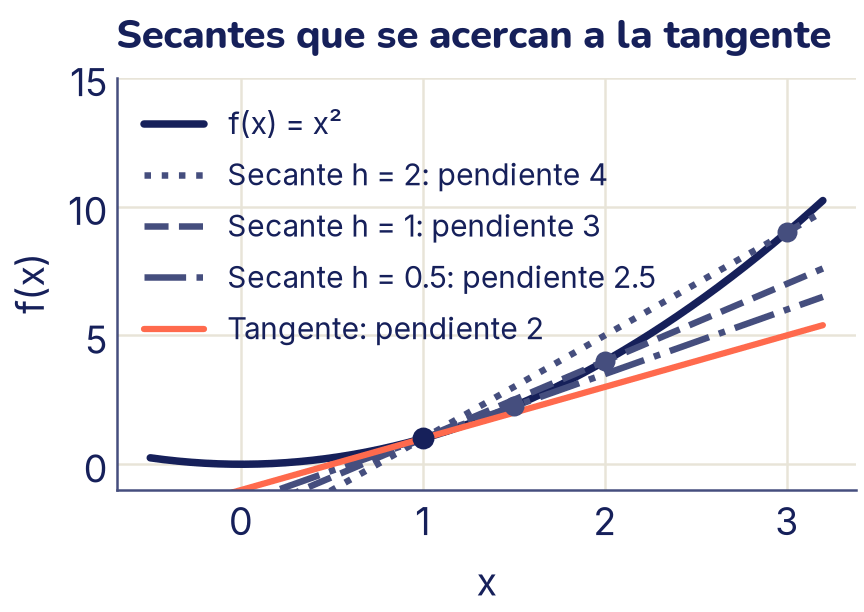

In [ ]:
a = 1
xs = np.linspace(-0.5, 3.2, 200)
plt.plot(xs, f(xs), color="C0", linewidth=3, label="f(x) = x²")
for h, estilo in [(2, ":"), (1, "--"), (0.5, "-.")]:
    m = pendiente_secante(f, a, h)
    plt.plot(xs, f(a) + m * (xs - a), color="C2", linestyle=estilo,
             label=f"Secante h = {h}: pendiente {m:g}")
    plt.scatter([a + h], [f(a + h)], color="C2", zorder=3)
# La tangente: la recta por (1, 1) con pendiente 2
plt.plot(xs, f(a) + 2 * (xs - a), color="C1", linewidth=2.5,
         label="Tangente: pendiente 2")
plt.scatter([a], [f(a)], color="C0", s=60, zorder=4)
plt.ylim(-1, 15)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Secantes que se acercan a la tangente")
plt.legend(fontsize=12, loc="upper left")
plt.show()

### La derivada

La **derivada** de *f* en *a*, que se escribe *f*′(*a*), es el número al que se acercan las pendientes de las secantes cuando *h* se hace cada vez más chico. En símbolos, es un **límite**:

$${f}^{'} ( a ) = \lim_{h \to 0} \frac{f ( a + h ) - f ( a )}{h}$$

Se lee así: **la derivada es la pendiente de la tangente**, o sea, qué tan rápido cambia *f* cuando *x* cambia un poquito. Para *f*(*x*) = *x*² la cuenta se puede hacer a mano: (*a* + *h*)² − *a*² = 2*ah* + *h*², y al dividir por *h* queda 2*a* + *h*, que se acerca a 2*a*. Por eso *f*′(*x*) = 2*x*, y en *a* = 1 vale 2, como vimos.

Con cuentas parecidas se obtiene una regla para cualquier potencia, la **regla de la potencia**: el exponente baja a multiplicar y el nuevo exponente es uno menos.

| Función | Derivada exacta | Ejemplo |
|---|---|---|
| *x*<sup>*n*</sup> | *n* · *x*<sup>*n* − 1</sup> | *x*² → 2*x*;  *x*³ → 3*x*² |

Dos reglas más completan lo que vamos a necesitar: la derivada de una suma es la suma de las derivadas, y un número que multiplica se queda tal cual. Por ejemplo, *x*³/3 − *x* tiene derivada 3*x*²/3 − 1 = *x*² − 1 (la derivada de *x* = *x*<sup>1</sup> es 1 · *x*<sup>0</sup> = 1).

Lo que dice la derivada se lee en su signo:

- **Positiva:** la curva sube hacia la derecha. Si *x* aumenta un poquito, *f* aumenta.
- **Negativa:** la curva baja hacia la derecha.
- **Cero:** la curva está plana en ese punto. Pasa en el fondo de un valle (un **mínimo**) y en la cima de un cerro (un **máximo**).

Esta última línea es la que más vamos a usar: **en el fondo del valle la pendiente vale cero**, y si la pendiente es positiva, para bajar hay que moverse hacia la izquierda (en contra de la pendiente).

### La derivada numérica

La computadora no necesita hacer el límite: le basta con un *h* muy chico. Hay una versión mejor que la secante «hacia adelante»: la **diferencia centrada**, que toma un punto a cada lado de *x*, en *x* − *h* y en *x* + *h*:

$${f}^{'} ( x ) \approx \frac{f ( x + h ) - f ( x - h )}{2 h}$$

Comparemos las dos con *x*³, cuya derivada exacta, por la regla de la potencia, es 3*x*² (en *x* = 2 vale 12):

In [ ]:
# 1e-6 es notación científica: 1 × 10 elevado a -6 = 0.000001
def derivada(f, x, h=1e-6):
    """Derivada numérica de f en x, con la diferencia centrada."""
    return (f(x + h) - f(x - h)) / (2 * h)

def cubo(x):
    return x ** 3

# La derivada exacta de x³ es 3x²: en x = 2 vale 12
for h in [0.1, 0.01, 0.001]:
    adelante = pendiente_secante(cubo, 2, h)
    centrada = derivada(cubo, 2, h)
    print(f"h = {h:<5}  hacia adelante: {adelante:.6f}   "
          f"centrada: {centrada:.6f}")
print(f"Centrada con h = 0.000001: {derivada(cubo, 2):.6f}")

h = 0.1    hacia adelante: 12.610000   centrada: 12.010000
h = 0.01   hacia adelante: 12.060100   centrada: 12.000100
h = 0.001  hacia adelante: 12.006001   centrada: 12.000001
Centrada con h = 0.000001: 12.000000


Con el mismo *h*, la diferencia centrada se equivoca muchísimo menos: con *h* = 0,1, la de adelante se pasa por 0,61 y la centrada solo por 0,01. Cuando *h* se divide por 10, el error de la de adelante también se divide por 10, pero el de la centrada se divide por 100. Por eso, desde ahora, nuestra función `derivada` usa la diferencia centrada con *h* = 0,000001. (Un *h* todavía más chico no siempre ayuda: la computadora guarda los números con unas 16 cifras, y restar dos números casi iguales pierde precisión.)

Ahora usemos la derivada para leer una curva. La de la actividad es *f*(*x*) = *x*³/3 − *x*:

In [ ]:
def curva(x):
    """La curva de la actividad: x³/3 − x."""
    return x ** 3 / 3 - x

for x in [-2, -1, 0, 1, 2]:
    m = derivada(curva, x)
    if abs(m) < 1e-6:
        forma = "está plana"
    elif m > 0:
        forma = "sube"
    else:
        forma = "baja"
    print(f"x = {x:>2}: pendiente {round(m, 4):>5}  -> la curva {forma}")

x = -2: pendiente   3.0  -> la curva sube
x = -1: pendiente   0.0  -> la curva está plana
x =  0: pendiente  -1.0  -> la curva baja
x =  1: pendiente   0.0  -> la curva está plana
x =  2: pendiente   3.0  -> la curva sube


Sube, se aplana en *x* = −1 (la cima de un cerrito), baja, se aplana otra vez en *x* = 1 (el fondo de un valle) y vuelve a subir. Eso es lo que viste al arrastrar el punto. La derivada exacta, que calculamos arriba con la regla de la potencia, es *x*² − 1, que vale cero justo en −1 y en 1.

## La regla de la cadena: engranajes

Muchas funciones están hechas de otras, una adentro de otra. Por ejemplo, (3*x* + 1)² es «elevar al cuadrado» aplicado a «3*x* + 1». ¿Cómo se deriva?

Piensa en dos **engranajes**. Cuando *x* da una vuelta, el engranaje de adentro, *u* = 3*x* + 1, da 3 vueltas. Y cada vuelta de *u* hace girar al de afuera, *u*², tantas vueltas como diga su derivada, 2*u*. En total, las velocidades **se multiplican**:

$$\frac{d y}{d x} = \frac{d y}{d u} \cdot \frac{d u}{d x}$$

Aquí *dy*/*dx* es otra forma de escribir la derivada de *y* respecto de *x*. Para *y* = (3*x* + 1)²: la derivada de afuera es 2*u* = 2(3*x* + 1) y la de adentro es 3, así que la derivada es 2(3*x* + 1) · 3. En *x* = 1 da 2 · 4 · 3 = 24. Comprobémoslo:

In [ ]:
def adentro(x):
    return 3 * x + 1

def afuera(u):
    return u ** 2

def compuesta(x):
    return afuera(adentro(x))

x0 = 1
u0 = adentro(x0)                      # u0 = 4
print("Engranaje de afuera, derivada de u² en u = 4:",
      round(derivada(afuera, u0), 4))
print("Engranaje de adentro, d(3x+1):    ", round(derivada(adentro, x0), 4))
print("Producto (regla de la cadena):    ",
      round(derivada(afuera, u0) * derivada(adentro, x0), 4))
print("Derivada numérica directa:        ", round(derivada(compuesta, x0), 4))

Engranaje de afuera, derivada de u² en u = 4: 8.0
Engranaje de adentro, d(3x+1):     3.0
Producto (regla de la cadena):     24.0
Derivada numérica directa:         24.0


La regla de la cadena es la que, en el tema 6, te va a permitir derivar el error de un modelo («la derivada de algo al cuadrado es 2 por ese algo, por la derivada de lo de adentro»), y en las redes neuronales se aplica capa por capa.

## Dos variables: derivadas parciales y gradiente

Un modelo casi nunca tiene una sola perilla. Veamos una función de **dos** variables:

$$g ( x , y ) = {x}^{2} + 3 {y}^{2}$$

Su gráfica es una superficie con forma de cuenco, con el fondo en (0, 0). Para dibujarla en papel se usan **curvas de nivel**, como en un mapa topográfico: cada curva une los puntos donde *g* vale lo mismo. Las curvas de *g* son elipses, más angostas en la dirección de *y*, porque ahí el cuenco es más empinado.

¿Cuál es la pendiente de una superficie? Depende de la dirección en que camines. Hay dos direcciones fáciles:

- La **derivada parcial respecto de *x***, que se escribe ∂*g*/∂*x*, es la pendiente cuando te mueves solo en *x*, con *y* quieta. Se calcula derivando como siempre y tratando a *y* como un número fijo: ∂*g*/∂*x* = 2*x*.
- La **derivada parcial respecto de *y***, ∂*g*/∂*y*, es la pendiente cuando te mueves solo en *y*, con *x* quieta: ∂*g*/∂*y* = 6*y*.

El **gradiente** junta las dos en un vector (una flecha), y se escribe con el símbolo ∇ («nabla»):

$$\nabla g = ( \frac{\partial g}{\partial x} , \frac{\partial g}{\partial y} ) = ( 2 x , 6 y )$$

Numéricamente, cada derivada parcial es una derivada centrada en la que solo se mueve una variable:

In [ ]:
def g(x, y):
    """Un cuenco alargado: g(x, y) = x² + 3y²."""
    return x ** 2 + 3 * y ** 2

def gradiente_numerico(f, x, y, h=1e-6):
    """Las dos derivadas parciales de f en (x, y), juntas en un vector."""
    df_dx = (f(x + h, y) - f(x - h, y)) / (2 * h)
    df_dy = (f(x, y + h) - f(x, y - h)) / (2 * h)
    return np.array([df_dx, df_dy])

print("Gradiente numérico en (2, 1):",
      np.round(gradiente_numerico(g, 2, 1), 4))
print("Gradiente exacto (2x, 6y):   ", np.array([2 * 2, 6 * 1]))

Gradiente numérico en (2, 1): [4. 6.]
Gradiente exacto (2x, 6y):    [4 6]


### El gradiente apunta cuesta arriba

El gradiente tiene una propiedad que lo hace famoso: **apunta en la dirección en que la función sube más rápido**, y su largo dice qué tan empinada es esa subida. No hace falta creerlo: probemos las 360 direcciones posibles (una por grado) desde el punto (2, 1), con pasos todos del mismo largo, y veamos cuál sube más.

In [ ]:
punto = np.array([2.0, 1.0])
# *punto pasa los dos números por separado: es como escribir 2.0, 1.0
grad = gradiente_numerico(g, *punto)
paso = 1e-4                           # un paso muy corto
angulos = np.arange(360)              # una dirección por grado
# NumPy mide los ángulos en radianes: 180 grados son π radianes
rad = np.deg2rad(angulos)
# cos y sin de un ángulo dan una flecha de largo 1 en esa dirección;
# column_stack las pone una por fila: forma (360, 2)
direcciones = np.column_stack([np.cos(rad), np.sin(rad)])
subidas = [g(*(punto + paso * d)) - g(*punto) for d in direcciones]

print("Dirección en que g sube más:", angulos[np.argmax(subidas)],
      "grados")
# arctan2(y, x) da el ángulo de la flecha (x, y), y degrees lo pasa a grados
angulo_grad = np.degrees(np.arctan2(grad[1], grad[0]))
print(f"Dirección del gradiente:     {angulo_grad:.1f} grados")
print(f"Mayor subida dividida por el paso: {max(subidas) / paso:.3f}")
print(f"Largo del gradiente:               {np.linalg.norm(grad):.3f}")

Dirección en que g sube más: 56 grados
Dirección del gradiente:     56.3 grados
Mayor subida dividida por el paso: 7.211
Largo del gradiente:               7.211


La mejor dirección entre las 360 es la del gradiente (redondeada al grado), y la subida por unidad de paso coincide con el largo del gradiente. En la dirección **contraria** al gradiente, la función **baja** lo más rápido posible. Ese es todo el truco del descenso de gradiente del tema 6: calcular el gradiente del error y dar un paso en contra.

El gráfico dibuja las curvas de nivel de *g* y el gradiente en una cuadrícula de puntos. Las flechas están achicadas a la décima parte para que quepan.

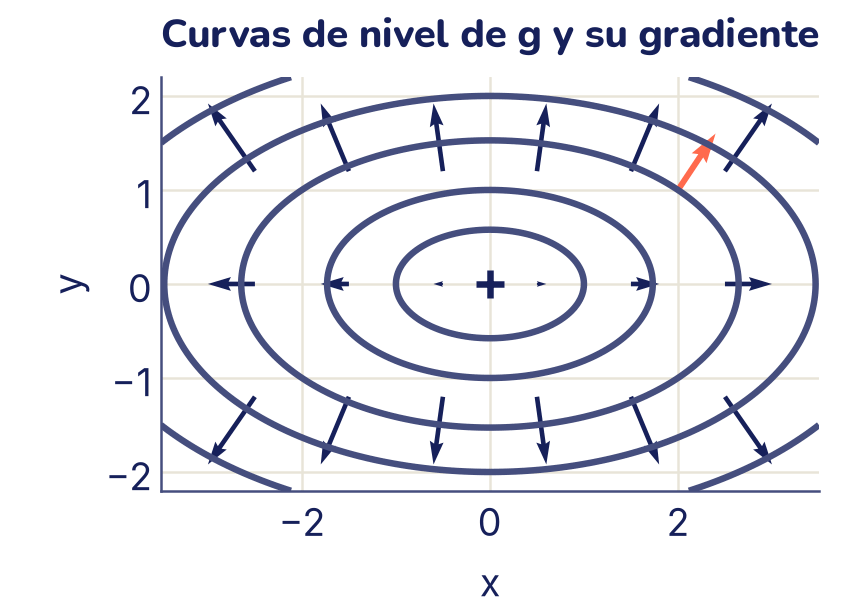

In [ ]:
xs = np.linspace(-3.5, 3.5, 200)
ys = np.linspace(-2.2, 2.2, 200)
XX, YY = np.meshgrid(xs, ys)
plt.contour(XX, YY, g(XX, YY), levels=[1, 3, 7, 12, 19], colors="C2")

# Flechas del gradiente en una cuadrícula de puntos
xq, yq = np.meshgrid(np.arange(-2.5, 3, 1), [-1.2, 0, 1.2])
gx, gy = gradiente_numerico(g, xq, yq)
plt.quiver(xq, yq, gx, gy, color="C0", angles="xy",
           scale_units="xy", scale=10, width=0.007)
# El gradiente en (2, 1), sobre la curva de nivel g = 7
plt.quiver([2], [1], [grad[0]], [grad[1]], color="C1", angles="xy",
           scale_units="xy", scale=10, width=0.009)
plt.scatter([0], [0], marker="+", s=120, color="C0")
plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Curvas de nivel de g y su gradiente")
plt.show()

Fíjate en tres cosas, las mismas de la actividad:

1. Cada flecha cruza su curva de nivel en **ángulo recto**. Caminar a lo largo de una curva de nivel no cambia *g*; el gradiente apunta hacia donde cambia más.
2. Las flechas son **más largas lejos del fondo**, donde el cuenco es más empinado, y casi nulas cerca de (0, 0). En el mínimo, el gradiente es cero.
3. Como el cuenco es alargado, las flechas **no apuntan justo hacia afuera** desde el centro: se inclinan hacia la dirección más empinada, la de *y*. Bajar en contra del gradiente no lleva en línea recta al fondo. Eso explica el camino en zigzag que verás en el tema 6.

## Promedios: media, varianza y desviación estándar

Cambiemos de tema: de pendientes a datos. Dos estudiantes, Sofía y Mateo, anotaron cuántos minutos tardaron en llegar al colegio durante cinco días:

In [ ]:
# Minutos de viaje al colegio durante cinco días
sofia = np.array([20, 22, 19, 21, 18])
mateo = np.array([10, 35, 15, 30, 10])
print("Sofía:", sofia.mean(), "minutos en promedio")
print("Mateo:", mateo.mean(), "minutos en promedio")

Sofía: 20.0 minutos en promedio
Mateo: 20.0 minutos en promedio


Los dos tardan, en promedio, 20 minutos. Pero no es lo mismo: Sofía llega casi siempre a la misma hora y Mateo a veces vuela y a veces se atrasa mucho. La **media** (el promedio) dice dónde está el centro de los datos; necesitamos otro número que diga qué tan **dispersos** están alrededor de ese centro.

La **varianza** es el promedio de las distancias a la media, elevadas al cuadrado (para que las de abajo no cancelen a las de arriba). Como queda en «minutos al cuadrado», se usa su raíz, la **desviación estándar**, que vuelve a estar en minutos. Con *n* datos *x*<sub>1</sub>, …, *x*<sub>n</sub>:

$$\overline{x} = \frac{1}{n} \sum_{i = 1}^{n} {x}_{i}$$

  
$${\sigma}^{2} = \frac{1}{n} \sum_{i = 1}^{n} {( {x}_{i} - \overline{x} )}^{2}$$

  
$$\sigma = \sqrt{{\sigma}^{2}}$$

*x̄* se lee «x barra» y *σ* es la letra griega sigma (la minúscula). La Σ grande es la sigma mayúscula y significa «suma»: Σ<sub>*i*=1</sub><sup>*n*</sup> *x*<sub>*i*</sub> quiere decir «suma *x*<sub>*i*</sub> para *i* = 1, 2, …, *n*», o sea *x*<sub>1</sub> + *x*<sub>2</sub> + … + *x*<sub>*n*</sub>. Con los minutos de Sofía (*n* = 5), Σ *x*<sub>*i*</sub> = 20 + 22 + 19 + 21 + 18 = 100, y la media es 100/5 = 20. En la varianza, lo que se suma es (*x*<sub>*i*</sub> − *x̄*)²: (20 − 20)² + (22 − 20)² + (19 − 20)² + (21 − 20)² + (18 − 20)² = 0 + 4 + 1 + 1 + 4 = 10, y 10/5 = 2. Programado tal cual:

In [ ]:
for nombre, t in [("Sofía", sofia), ("Mateo", mateo)]:
    media = t.mean()
    varianza = np.mean((t - media) ** 2)
    desviacion = np.sqrt(varianza)
    print(f"{nombre}: media {media:.1f}   varianza {varianza:.1f}   "
          f"desviación {desviacion:.2f}")

print("Con NumPy:", np.var(mateo), round(np.std(mateo), 2))

Sofía: media 20.0   varianza 2.0   desviación 1.41
Mateo: media 20.0   varianza 110.0   desviación 10.49
Con NumPy: 110.0 10.49


Sofía se aleja de su media unos 1,4 minutos «típicos»; Mateo, unos 10,5. `np.var` y `np.std` dan lo mismo que nuestra fórmula.

Un detalle que confunde a todo el mundo: algunas herramientas dividen por *n* − 1 en lugar de *n* (por razones que verás en estadística). NumPy divide por *n*, como nosotros; **pandas divide por *n* − 1**. Para que pandas haga lo mismo que NumPy, escribe `.std(ddof=0)`.

### El puntaje z y la estandarización

¿Qué es más raro: que Sofía tarde 23 minutos o que Mateo tarde 40? Mateo se pasa más de su media (20 minutos contra 3), pero él varía mucho más. Para comparar hay que medir la distancia a la media **en desviaciones estándar**. Eso es el **puntaje z**:

$$z = \frac{x - \overline{x}}{\sigma}$$

In [ ]:
z_sofia = (23 - sofia.mean()) / sofia.std()
z_mateo = (40 - mateo.mean()) / mateo.std()
print(f"23 minutos para Sofía: z = {z_sofia:.2f}")
print(f"40 minutos para Mateo: z = {z_mateo:.2f}")

23 minutos para Sofía: z = 2.12
40 minutos para Mateo: z = 1.91


Sofía tardando 23 minutos está a 2,12 desviaciones de lo habitual para ella; Mateo tardando 40, a 1,91. Lo de Sofía es más raro, aunque sean menos minutos.

**Estandarizar** una columna de datos es reemplazar cada valor por su puntaje z. La columna nueva siempre queda con **media 0 y desviación estándar 1**, sin importar en qué unidades estaba:

In [ ]:
z = (mateo - mateo.mean()) / mateo.std()
print("Mateo estandarizado:", np.round(z, 2))
print(f"Media: {abs(z.mean()):.2f}   desviación: {z.std():.2f}")

Mateo estandarizado: [-0.95  1.43 -0.48  0.95 -0.95]
Media: 0.00   desviación: 1.00


¿Para qué sirve? Para poner en la misma escala datos que vienen en unidades muy distintas. En una tabla con la estatura en centímetros y el peso en kilos, un modelo no debería tratar a una columna como más importante solo porque sus números son más grandes. En el tema 6 vas a ver que, además, estandarizar hace que el descenso de gradiente llegue mucho más rápido.

### Una tabla entera: vectores y matrices

En el tema 3 viste que una tabla de números es una **matriz**: cada fila, un ejemplo; cada columna, una característica. Y que cada fila (o columna) es un **vector**. El gradiente que calculamos arriba también es un vector. Con `axis=0`, NumPy saca la media y la desviación de cada columna, y la resta y la división se aplican columna por columna. Así se estandariza una tabla entera en una línea:

In [ ]:
# Cuatro estudiantes: estatura (cm) y peso (kg)
tabla = np.array([[150, 45], [160, 52], [170, 61], [180, 70]],
                 dtype=float)
tabla_est = (tabla - tabla.mean(axis=0)) / tabla.std(axis=0)

print("Medias por columna:", tabla.mean(axis=0))
print("Desviaciones:", np.round(tabla.std(axis=0), 2))
print(np.round(tabla_est, 2))

Medias por columna: [165.  57.]
Desviaciones: [11.18  9.41]
[[-1.34 -1.28]
 [-0.45 -0.53]
 [ 0.45  0.43]
 [ 1.34  1.38]]


Ahora las dos columnas hablan el mismo idioma: un 1 significa «una desviación estándar por encima del promedio», sea en estatura o en peso.

## Azar: probabilidad como frecuencia

¿Qué quiere decir que la probabilidad de sacar un 6 con un dado es 1/6? Una forma muy práctica de entenderlo: si tiras el dado **muchísimas veces**, la fracción de tiros que salen 6 se acerca a 1/6. A esa fracción se le llama **frecuencia relativa**.

Con la computadora podemos tirar un dado cien mil veces en un instante. `rng.integers(1, 7)` da enteros del 1 al 6 (el 7 no entra), todos igual de probables:

In [ ]:
rng = np.random.default_rng(7)
tiros = rng.integers(1, 7, size=100_000)
print("Primeros diez tiros:", tiros[:10])

for n in [10, 100, 1_000, 10_000, 100_000]:
    fraccion = np.mean(tiros[:n] == 6)
    print(f"{n:>7} tiros: fracción de seises = {fraccion:.4f}")
print(f"Probabilidad: 1/6 = {1 / 6:.4f}")

Primeros diez tiros: [6 4 5 6 4 5 6 2 1 2]
     10 tiros: fracción de seises = 0.3000
    100 tiros: fracción de seises = 0.2000
   1000 tiros: fracción de seises = 0.1800
  10000 tiros: fracción de seises = 0.1690
 100000 tiros: fracción de seises = 0.1682
Probabilidad: 1/6 = 0.1667


Con pocos tiros la fracción salta mucho; con muchos se queda pegada a 1/6. Eso se llama **ley de los grandes números**: el promedio de muchos experimentos al azar se acerca a la probabilidad. Lo vemos mejor siguiendo la fracción tiro a tiro:

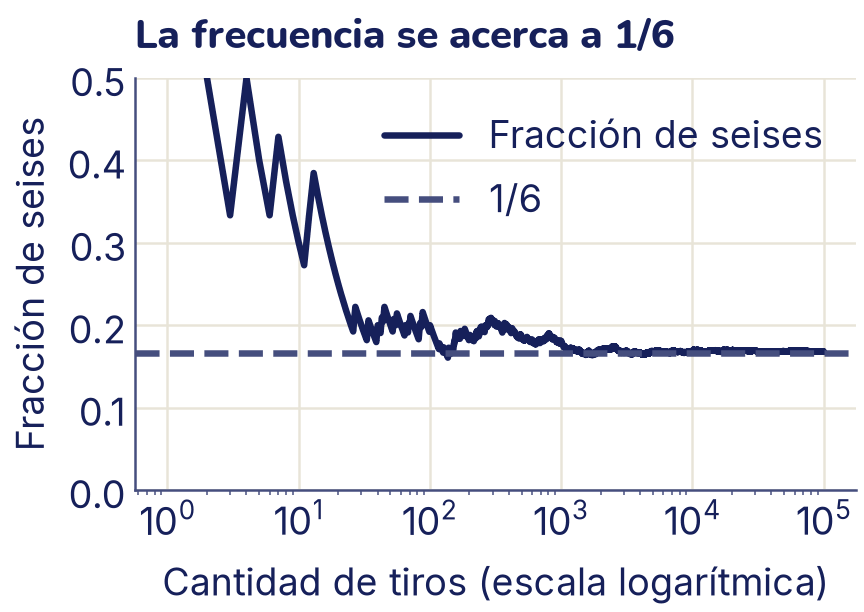

In [ ]:
n_tiros = np.arange(1, len(tiros) + 1)
# Fracción de seises acumulada después de cada tiro
frecuencia = np.cumsum(tiros == 6) / n_tiros
plt.plot(n_tiros, frecuencia, color="C0", label="Fracción de seises")
plt.axhline(1 / 6, color="C2", linestyle="--", label="1/6")
plt.xscale("log")
plt.ylim(0, 0.5)
plt.xlabel("Cantidad de tiros (escala logarítmica)")
plt.ylabel("Fracción de seises")
plt.title("La frecuencia se acerca a 1/6")
plt.legend()
plt.show()

La escala logarítmica del eje horizontal pone 1, 10, 100, 1000… a la misma distancia, para que se vean a la vez los primeros tiros y los últimos. (Vas a entender por qué al final del tema.)

## Probabilidad condicional y la regla de Bayes

A veces la probabilidad cambia cuando sabemos algo más. La **probabilidad condicional** P(A | B) se lee «la probabilidad de A **sabiendo que** pasó B». Por ejemplo, la probabilidad de que llueva es una; la probabilidad de que llueva sabiendo que el cielo está cubierto de nubes negras es otra, mucho mayor.

Un ejemplo médico muestra por qué importa. Una enfermedad la tiene **1 de cada 100** personas. Hay una prueba para detectarla:

- si la persona **tiene** la enfermedad, la prueba sale positiva el **90 %** de las veces;
- si **no** la tiene, igual sale positiva (por error) el **5 %** de las veces.

A una persona tomada al azar le sale **positivo**. ¿Qué probabilidad hay de que tenga la enfermedad? Mucha gente responde «90 %». Pensemos en **10 000 personas**:

- 100 tienen la enfermedad, y a 90 de ellas les sale positivo;
- 9900 no la tienen, y a 5 % de ellas, 495, también les sale positivo.

En total hay 90 + 495 = 585 positivos, y solo 90 están enfermos: 90/585 ≈ **15,4 %**. La prueba no es mala; lo que pasa es que hay tantas personas sanas que sus pocos errores suman más que los enfermos de verdad. Eso es la **regla de Bayes**:

$$P ( A | B ) = \frac{P ( B | A ) \cdot P ( A )}{P ( B )}$$

Con A = «está enferma» y B = «sale positivo»: P(B | A) = 0,9 y P(A) = 0,01, así que el numerador es 0,009. P(B), la probabilidad de salir positivo, suma los dos caminos: 0,9 · 0,01 + 0,05 · 0,99 = 0,0585. Y 0,009/0,0585 ≈ 0,154. Ahora comprobémoslo **simulando** un millón de personas:

In [ ]:
N = 1_000_000                         # personas simuladas
p_enfermedad = 0.01                   # 1 de cada 100
sensibilidad = 0.90                   # P(positivo | enferma)
falso_positivo = 0.05                 # P(positivo | sana)

rng = np.random.default_rng(1)
enferma = rng.random(N) < p_enfermedad
azar = rng.random(N)
# A cada persona le sale positivo con la probabilidad que le toca
positivo = np.where(enferma, azar < sensibilidad, azar < falso_positivo)

print("Personas con resultado positivo:", positivo.sum())
print(f"P(enferma | positivo) simulada: {enferma[positivo].mean():.4f}")
p_positivo = (sensibilidad * p_enfermedad
              + falso_positivo * (1 - p_enfermedad))
print(f"P(enferma | positivo) con Bayes: "
      f"{sensibilidad * p_enfermedad / p_positivo:.4f}")

Personas con resultado positivo: 58896
P(enferma | positivo) simulada: 0.1534
P(enferma | positivo) con Bayes: 0.1538


La simulación y la fórmula difieren en menos de una milésima. `enferma[positivo]` se queda solo con las personas a las que les salió positivo, y su media es la fracción de enfermas entre ellas: eso **es** la probabilidad condicional, contada. Muchos modelos de clasificación hacen este mismo razonamiento: partir de lo común que es cada clase y actualizarlo con la evidencia.

## Distribuciones: uniforme, Bernoulli y normal

Una **distribución** dice qué valores puede tomar algo al azar y con qué probabilidad. Ya usaste tres:

- **Uniforme:** todos los valores igual de probables. El dado (1 a 6, cada uno con 1/6) y `rng.random()`, que da cualquier número entre 0 y 1 sin preferir ninguno.
- **Bernoulli:** un experimento con dos resultados, «sí» (1) con probabilidad *p* y «no» (0) con probabilidad 1 − *p*. Una moneda es Bernoulli con *p* = 0,5; «¿le sale positivo?» también es una Bernoulli. En código, `rng.random() < p`.
- **Normal:** la famosa **campana**. Aparece cuando algo es la suma de muchos efectos chicos al azar: las estaturas, los errores de medición, las notas de un curso grande.

La normal tiene dos parámetros: su media *μ* (mu), donde está el centro, y su desviación estándar *σ*, el ancho. Su fórmula no hace falta memorizarla; usa la exponencial, exp, que verás en la sección siguiente:

$$p ( x ) = \frac{1}{\sigma \sqrt{2 \pi}} \; \text{exp} ( - \frac{{( x - \mu )}^{2}}{2 {\sigma}^{2}} )$$

Lo que sí conviene recordar es la **regla 68–95–99,7**: en una normal, más o menos el 68 % de los datos queda a menos de una desviación estándar de la media, el 95 % a menos de dos y el 99,7 % a menos de tres. Probémoslo con estaturas simuladas de media 165 cm y desviación 7 cm:

In [ ]:
rng = np.random.default_rng(5)
estaturas = rng.normal(165, 7, size=100_000)
print(f"Media: {estaturas.mean():.2f}   "
      f"desviación: {estaturas.std():.2f}")

z = (estaturas - estaturas.mean()) / estaturas.std()
for k in [1, 2, 3]:
    print(f"Fracción con |z| menor que {k}: {np.mean(np.abs(z) < k):.3f}")

Media: 165.01   desviación: 6.99
Fracción con |z| menor que 1: 0.682
Fracción con |z| menor que 2: 0.955
Fracción con |z| menor que 3: 0.997


### Por qué aparece tanto la campana

Tira un dado: cada número sale con la misma probabilidad, sin ninguna campana. Pero si tiras dos dados y sumas, el 7 sale mucho más que el 2 o el 12 (hay más formas de sumar 7). Con más dados, las sumas forman una campana cada vez más perfecta. Este resultado, el **teorema central del límite**, explica por qué la normal está en todas partes: lo que se forma sumando muchas partes al azar termina pareciéndose a una campana.

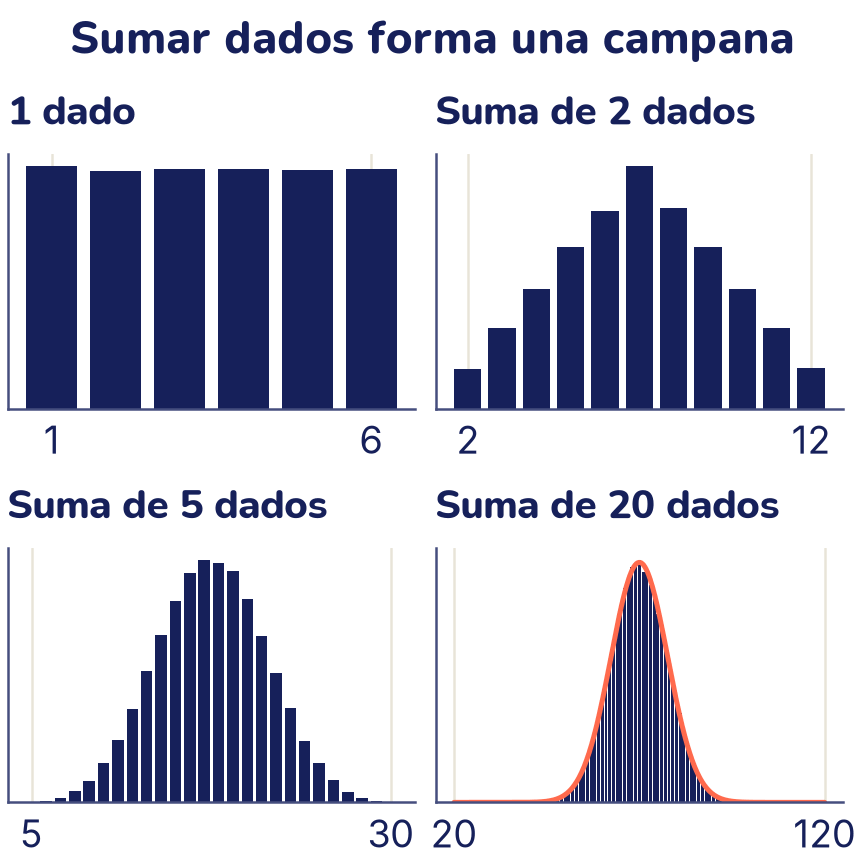

In [ ]:
def densidad_normal(x, mu, sigma):
    """La fórmula de la campana."""
    return (np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))
            / (sigma * np.sqrt(2 * np.pi)))

rng = np.random.default_rng(3)
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, k in zip(ejes.flat, [1, 2, 5, 20]):
    # 100 000 tiradas de k dados, sumando cada tirada
    sumas = rng.integers(1, 7, size=(100_000, k)).sum(axis=1)
    valores, cuentas = np.unique(sumas, return_counts=True)
    eje.bar(valores, cuentas / len(sumas), width=0.8, color="C0")
    eje.set_title("1 dado" if k == 1 else f"Suma de {k} dados")
    eje.set_xticks([k, 6 * k])          # la menor y la mayor suma
    eje.set_yticks([])

# Un dado tiene media 3,5 y varianza 35/12; con k dados, k veces eso
xs = np.linspace(20, 120, 300)
eje.plot(xs, densidad_normal(xs, 3.5 * k, np.sqrt(35 / 12 * k)),
         color="C1", linewidth=2)
fig.suptitle("Sumar dados forma una campana")
plt.show()

La curva del último panel no se ajustó a los datos: es la normal con la media y la desviación que la teoría predice para la suma de 20 dados (media 20 · 3,5 = 70, varianza 20 · 35/12). Y aun así coincide con las barras. Ojo: la campana aparece al **sumar** muchos efectos independientes. No todo en el mundo es normal: los ingresos de las personas, por ejemplo, tienen una cola larga hacia la derecha.

## Logaritmo y exponencial

La **exponencial** exp(*x*) = *e*<sup>*x*</sup> es la potencia de un número especial, *e* ≈ 2,718. Crece muy rápido y siempre es positiva. El **logaritmo natural**, log(*x*), es su operación inversa: responde «¿a qué potencia hay que elevar *e* para obtener *x*?». Por eso log(exp(*x*)) = *x*, y log solo acepta números positivos. En NumPy son `np.exp` y `np.log`. Ojo con la notación: en el colegio el logaritmo natural se escribe **ln**, y log suele ser el de base 10, el de la tecla «log» de la calculadora. En NumPy (y en toda la ruta), `log` es el natural, el ln del colegio; el de base 10 es `np.log10`. Si compruebas log(10) con la calculadora y te sale 1, usaste la base 10; con la tecla «ln» sale 2,3026, como abajo.

In [ ]:
print("e =", np.e)
print("exp(1) =", np.exp(1), "  log(e) =", np.log(np.e))
print("log(exp(5)) =", np.log(np.exp(5)))
print("exp(10) =", round(np.exp(10), 1), "  log(10) =",
      round(np.log(10), 4))

e = 2.718281828459045
exp(1) = 2.718281828459045   log(e) = 1.0
log(exp(5)) = 5.0
exp(10) = 22026.5   log(10) = 2.3026


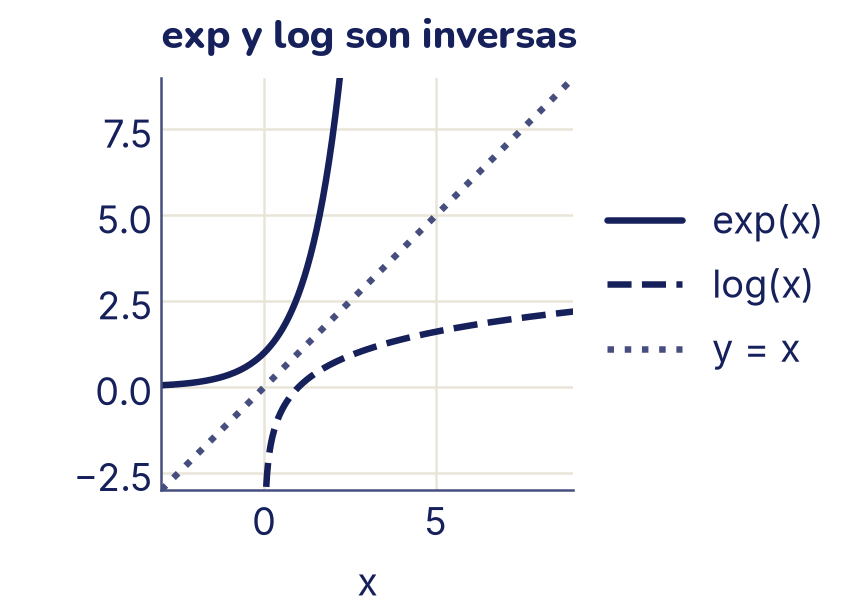

In [ ]:
xs = np.linspace(-3, 3, 200)
plt.plot(xs, np.exp(xs), color="C0", label="exp(x)")
xs_pos = np.linspace(0.02, 9, 300)     # log solo acepta positivos
plt.plot(xs_pos, np.log(xs_pos), color="C0", linestyle="--",
         label="log(x)")
plt.plot([-3, 9], [-3, 9], color="C2", linestyle=":",
         label="y = x")
plt.xlim(-3, 9)
plt.ylim(-3, 9)
plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.title("exp y log son inversas")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

Cada curva es el reflejo de la otra en la recta *y* = *x*, como pasa con toda función y su inversa.

### El logaritmo convierte productos en sumas

La propiedad más útil del logaritmo es esta:

$$\log ( a \cdot b ) = \log ( a ) + \log ( b )$$

¿Por qué? Porque al multiplicar potencias de la misma base, los exponentes se suman: *e*<sup>*u*</sup> · *e*<sup>*v*</sup> = *e*<sup>*u* + *v*</sup>. Si *a* = *e*<sup>*u*</sup> y *b* = *e*<sup>*v*</sup>, entonces log(*a*) = *u*, log(*b*) = *v* y *a* · *b* = *e*<sup>*u* + *v*</sup>, así que log(*a* · *b*) = *u* + *v*. El logaritmo «baja» los exponentes, y lo que era multiplicar pasa a ser sumar.

In [ ]:
print("log(6 · 8)      =", round(np.log(6 * 8), 6))
print("log(6) + log(8) =", round(np.log(6) + np.log(8), 6))

# La probabilidad de 1000 sucesos independientes, cada uno de 1 %
probabilidades = np.full(1000, 0.01)
print("Producto directo:", np.prod(probabilidades))
print("Suma de logaritmos:", round(np.sum(np.log(probabilidades)), 2))

log(6 · 8)      = 3.871201
log(6) + log(8) = 3.871201
Producto directo: 0.0
Suma de logaritmos: -4605.17


El producto da **0**, y está mal: el número verdadero es 10<sup>−2000</sup>, que es positivo pero demasiado chico para que la computadora lo guarde, así que lo redondea a cero. La suma de logaritmos, −4605,17, no tiene ese problema. Por eso, cuando un modelo multiplica muchas probabilidades (lo vas a ver en la regresión logística y en los modelos de lenguaje), en la práctica **suma sus logaritmos**. Además, sumar es más fácil de derivar que multiplicar.

Esto también explica la escala logarítmica del gráfico de los dados: como log(10 · *x*) = log(10) + log(*x*), multiplicar por 10 siempre suma lo mismo, log(10). Por eso, en un eje logarítmico, 1, 10, 100 y 1000 quedan a la misma distancia.

Un último dato que conecta todo el tema: la exponencial es **su propia derivada**. Su pendiente en cada punto es igual a su altura:

In [ ]:
for x in [0, 1, 2]:
    print(f"x = {x}: exp(x) = {np.exp(x):.4f}   "
          f"pendiente = {derivada(np.exp, x):.4f}")

x = 0: exp(x) = 1.0000   pendiente = 1.0000
x = 1: exp(x) = 2.7183   pendiente = 2.7183
x = 2: exp(x) = 7.3891   pendiente = 7.3891


## Lo que aprendiste y lo que sigue

- La **derivada** es la pendiente de la tangente: el límite de las pendientes de las secantes cuando *h* se achica. Con código se aproxima con la **diferencia centrada**. Su signo dice si la curva sube o baja, y vale cero en los mínimos y máximos.
- La **regla de la cadena** multiplica las derivadas de funciones encadenadas, como engranajes.
- Con dos variables, las **derivadas parciales** forman el **gradiente**, una flecha que apunta **cuesta arriba**, perpendicular a las curvas de nivel. En contra del gradiente, la función baja lo más rápido posible.
- La **media** dice dónde está el centro de los datos y la **desviación estándar**, qué tan dispersos están. **Estandarizar** (restar la media y dividir por la desviación) deja cualquier columna con media 0 y desviación 1.
- La **probabilidad** se puede estimar simulando y contando frecuencias. La **regla de Bayes** actualiza una probabilidad con la evidencia, y puede dar resultados muy distintos de la intuición.
- La **normal** aparece al sumar muchos efectos al azar. El **logaritmo** convierte productos en sumas y evita que los productos de muchas probabilidades se vuelvan cero.

En el tema 6 todo esto se junta: el error de un modelo es una función de sus parámetros, su gradiente apunta cuesta arriba y el modelo aprende dando pasos en contra. Las características se estandarizan antes de empezar, para que el camino sea corto.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las funciones de la teoría: `pendiente_secante`, `derivada`, `curva`, `gradiente_numerico` y `densidad_normal`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta: equivocarse primero y corregir después es como se aprende de verdad.

Para comparar con las derivadas exactas, estas reglas te bastan (*n* es cualquier número). La primera es la regla de la potencia de la teoría; las otras dos son las de la exponencial y el logaritmo natural (el ln del colegio):

| Función | Derivada exacta |
|---|---|
| *x*<sup>*n*</sup> | *n* · *x*<sup>*n* − 1</sup> |
| exp(*x*) | exp(*x*) |
| log(*x*) | 1/*x* |

## Ejercicios

### 1. Derivadas numéricas frente a exactas

Calcula con la regla de la tabla la derivada exacta de cada función en el punto indicado. Después calcula con código la pendiente de la secante hacia adelante (con *h* = 0,01) y la derivada centrada (con *h* = 0,01 y con el *h* por defecto), y compara.

1. *x*² en *x* = 3.
2. 1/*x* = *x*<sup>−1</sup> en *x* = 2.
3. log(*x*) en *x* = 0,5.

<details>
<summary>Respuesta</summary>

Las exactas: 2 · 3 = **6**; −1 · 2<sup>−2</sup> = **−0,25**; 1/0,5 = **2**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def inversa(x):
    return 1 / x

casos = [("x²", f, 3, 6), ("1/x", inversa, 2, -0.25),
         ("log(x)", np.log, 0.5, 2)]
print(f"{'':>13}{'exacta':>11}{'adelante':>11}{'centrada':>11}"
      f"{'fina':>11}")
for nombre, fun, x, exacta in casos:
    adelante = pendiente_secante(fun, x, 0.01)
    centrada = derivada(fun, x, 0.01)
    fina = derivada(fun, x)            # h = 0.000001
    print(f"{nombre + ' en ' + str(x):>13}{exacta:>11.6f}"
          f"{adelante:>11.6f}{centrada:>11.6f}{fina:>11.6f}")

<details>
<summary>Respuesta (sigue)</summary>

Con *h* = 0,01, la secante hacia adelante se equivoca ya en la segunda o tercera cifra decimal; la centrada, recién en la cuarta o más allá. Con *x*² la centrada da el valor exacto: con una parábola, la diferencia centrada nunca se equivoca. Con *h* = 0,000001, la centrada coincide con la exacta en las seis cifras que mostramos. La de log(*x*) en 0,5 es la que más error tiene, porque cerca de 0 el logaritmo se curva mucho.

</details>

### 2. Leer una pendiente

a) Usa `derivada` con la `curva` de la teoría (*x*³/3 − *x*) en *x* = −1,5, *x* = 0,5 y *x* = 1,5. Para cada punto, di si la curva sube o baja ahí y qué tan empinada es.

b) Se suelta una piedra desde 80 m de altura. Después de *t* segundos, su altura es 80 − 5*t*² metros. Calcula la derivada de la altura en *t* = 2. ¿Qué significan su signo y su valor?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for x in [-1.5, 0.5, 1.5]:
    print(f"x = {x:>4}: pendiente {derivada(curva, x):+.4f}")

def altura(t):
    return 80 - 5 * t ** 2

print(f"Derivada de la altura en t = 2: {derivada(altura, 2):.4f}")

<details>
<summary>Respuesta</summary>

a) En −1,5 y en 1,5 la pendiente es +1,25: la curva sube, y por cada unidad que avanzas a la derecha sube unas 1,25 unidades. En 0,5 la pendiente es −0,75: la curva baja, y menos empinada. Coincide con la derivada exacta *x*² − 1.

b) La derivada es −20. El signo negativo dice que la altura **disminuye**: la piedra cae. El valor dice **qué tan rápido**: en ese instante pierde 20 metros por cada segundo, es decir, cae a 20 m/s. La derivada de la posición respecto del tiempo es la **velocidad**.

</details>

### 3. La regla de la cadena

La función exp(−*x*²) es la forma de la campana normal. Es una cadena de dos engranajes: *u* = −*x*² adentro y exp(*u*) afuera.

a) Usa la regla de la cadena y la tabla de arriba para escribir su derivada.

b) Evalúala en *x* = 1 y compárala con la derivada numérica.

c) ¿Dónde vale cero esa derivada? ¿Qué pasa ahí con la campana?

<details>
<summary>Respuesta</summary>

a) La derivada de afuera es exp(*u*) y la de adentro es −2*x*. Multiplicando: la derivada es **−2*x* · exp(−*x*²)**.

b) En *x* = 1: −2 · exp(−1) ≈ −0,7358.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def campana(x):
    return np.exp(-x ** 2)

print(f"Con la regla de la cadena: {-2 * 1 * np.exp(-1):.4f}")
print(f"Derivada numérica:         {derivada(campana, 1):.4f}")

<details>
<summary>Respuesta (sigue)</summary>

c) −2*x* · exp(−*x*²) vale cero solo cuando *x* = 0, porque la exponencial nunca vale cero. Ahí la campana está plana: es su punto más alto, un **máximo**.

</details>

### 4. Un gradiente a mano

Sea *h*(*x*, *y*) = *x*² + *x*·*y* + 2*y*².

a) Calcula a mano las derivadas parciales ∂*h*/∂*x* y ∂*h*/∂*y*, y el gradiente en el punto (1, 1).

b) Compruébalo con `gradiente_numerico`.

c) Desde (1, 1), da un paso de largo 0,01 en tres direcciones: a favor del gradiente, en contra y perpendicular a él. ¿Cuánto cambia *h* en cada caso? Explica el resultado.

<details>
<summary>Respuesta</summary>

a) Para ∂*h*/∂*x*, *y* es un número fijo: la derivada de *x*² es 2*x*, la de *x*·*y* es *y* (como la de 3*x* es 3) y 2*y*² no cambia, así que su derivada es 0. Queda ∂*h*/∂*x* = 2*x* + *y*. Del mismo modo, ∂*h*/∂*y* = *x* + 4*y*. En (1, 1), el gradiente es **(3, 5)**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def h_xy(x, y):
    return x ** 2 + x * y + 2 * y ** 2

p = np.array([1.0, 1.0])
grad_h = gradiente_numerico(h_xy, *p)
print("Gradiente numérico en (1, 1):", np.round(grad_h, 4))

# Vectores de largo 1: a favor, en contra y perpendicular
unitario = grad_h / np.linalg.norm(grad_h)
perpendicular = np.array([-unitario[1], unitario[0]])
for nombre, d in [("a favor", unitario), ("en contra", -unitario),
                  ("perpendicular", perpendicular)]:
    cambio = h_xy(*(p + 0.01 * d)) - h_xy(*p)
    print(f"Paso {nombre:>13}: h cambia {cambio:+.5f}")
print(f"Largo del gradiente × 0.01:  {np.linalg.norm(grad_h) * 0.01:.5f}")

<details>
<summary>Respuesta (sigue)</summary>

c) A favor del gradiente, *h* **sube** casi exactamente «largo del gradiente × largo del paso»: es la mayor subida posible con ese paso. En contra, **baja** casi lo mismo: la mayor bajada posible. En la dirección perpendicular el cambio es casi cero: caminas a lo largo de la curva de nivel. (No es cero exacto porque las curvas de nivel están curvadas; con un paso más chico, el cambio perpendicular se achica mucho más rápido que los otros dos.)

</details>

### 5. Estandarizar una columna a mano

Ocho estudiantes respondieron cuántas horas durmieron anoche: 2, 4, 4, 4, 5, 5, 7 y 9 (sí, alguien durmió 2 horas).

a) Sin computadora, calcula la media, la varianza (dividiendo por *n*) y la desviación estándar.

b) Estandariza la columna: escribe el puntaje *z* de cada valor.

c) Compruébalo con NumPy. Después calcula la desviación con pandas (`pd.Series(datos).std()`) y explica por qué sale distinta.

<details>
<summary>Respuesta</summary>

a) La media es 40/8 = **5**. Las distancias a la media son −3, −1, −1, −1, 0, 0, 2 y 4; sus cuadrados suman 9 + 1 + 1 + 1 + 0 + 0 + 4 + 16 = 32. La varianza es 32/8 = **4** y la desviación estándar, √4 = **2**.

b) Cada *z* es la distancia a la media dividida por 2: **−1,5; −0,5; −0,5; −0,5; 0; 0; 1; 2**. Quien durmió 2 horas está a 1,5 desviaciones por debajo del promedio.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
import pandas as pd

datos = np.array([2, 4, 4, 4, 5, 5, 7, 9])
print("Media:", datos.mean(), "  varianza:", datos.var(),
      "  desviación:", datos.std())
print("z:", (datos - datos.mean()) / datos.std())
print(f"pandas, por defecto: {pd.Series(datos).std():.4f}")
print(f"pandas con ddof=0:   {pd.Series(datos).std(ddof=0):.4f}")

<details>
<summary>Respuesta (sigue)</summary>

c) NumPy da lo mismo que la cuenta a mano. pandas, por defecto, divide por *n* − 1 = 7 en lugar de por 8: √(32/7) ≈ 2,138. Con `ddof=0` divide por *n* y coincide con NumPy. Ninguna de las dos está «mal», pero hay que usar la misma en todo un trabajo.

</details>

### 6. Bayes: ¿y si sale positivo dos veces?

Sigue el ejemplo médico de la teoría (1 % de enfermos, la prueba detecta al 90 % de los enfermos y da falso positivo al 5 % de los sanos). A una persona le sale positivo y repite la prueba; **le vuelve a salir positivo**. Supón que los dos resultados son independientes entre sí, una vez que se sabe si la persona está enferma o sana.

a) Con 10 000 personas imaginarias, ¿cuántos enfermos y cuántos sanos sacan dos positivos? ¿Qué probabilidad hay de que una persona con dos positivos esté enferma?

b) Comprueba tu respuesta simulando un millón de personas.

<details>
<summary>Respuesta</summary>

a) De los 100 enfermos, sacan dos positivos 100 · 0,9 · 0,9 = 81. De los 9900 sanos, 9900 · 0,05 · 0,05 = 24,75 (en promedio). La probabilidad es 81/(81 + 24,75) ≈ **0,766**: con dos positivos, la sospecha sube del 15 % a casi el 77 %. Es la regla de Bayes aplicada dos veces: lo que salió del primer positivo (15,4 %) es el punto de partida del segundo.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
N = 1_000_000
rng = np.random.default_rng(2)
enferma = rng.random(N) < 0.01
# Cada prueba se decide con su propio número al azar
prob_pos = np.where(enferma, 0.90, 0.05)
prueba1 = rng.random(N) < prob_pos
prueba2 = rng.random(N) < prob_pos
dos_positivos = prueba1 & prueba2

print("Personas con dos positivos:", dos_positivos.sum())
print(f"Simulación: {enferma[dos_positivos].mean():.3f}")
formula = (0.01 * 0.9 ** 2) / (0.01 * 0.9 ** 2 + 0.99 * 0.05 ** 2)
print(f"Fórmula:    {formula:.3f}")

<details>
<summary>Respuesta (sigue)</summary>

La simulación (0,768) y la fórmula (0,766) coinciden en dos cifras: solo unas 10 000 personas sacaron dos positivos, así que la simulación tiene un margen de unas milésimas. Fíjate que `prob_pos` da a cada persona la probabilidad de positivo que le toca según esté enferma o sana; comparar `rng.random(N) < prob_pos` hace una Bernoulli distinta para cada una.

</details>

### 7. La normal y las estaturas

Supón que las estaturas de un grupo grande siguen una normal de media 165 cm y desviación 7 cm.

a) Sin computadora, con la regla 68–95–99,7: ¿qué fracción mide más de 179 cm? ¿Y entre 158 y 172 cm?

b) Compruébalo simulando 100 000 estaturas.

<details>
<summary>Respuesta</summary>

a) 179 está a (179 − 165)/7 = 2 desviaciones por encima de la media. Entre −2 y +2 desviaciones queda el 95 %; el 5 % restante se reparte por igual entre las dos colas, así que más de 179 cm mide alrededor del **2,5 %** (el valor exacto es 2,3 %). Entre 158 y 172 cm es estar a menos de una desviación de la media: alrededor del **68 %**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
rng = np.random.default_rng(8)
alturas = rng.normal(165, 7, size=100_000)
print(f"Más de 179 cm:       {np.mean(alturas > 179):.3f}")
print(f"Entre 158 y 172 cm:  {np.mean((alturas > 158) & (alturas < 172)):.3f}")

<details>
<summary>Respuesta (sigue)</summary>

Las fracciones simuladas quedan muy cerca de 0,023 y de 0,683, los valores exactos de la normal.

</details>

### 8. Logaritmos al rescate

a) Comprueba con NumPy que log(*a*/*b*) = log(*a*) − log(*b*) para *a* = 50 y *b* = 4, y explica por qué pasa, usando que *e*<sup>*u*</sup>/*e*<sup>*v*</sup> = *e*<sup>*u* − *v*</sup>.

b) Tiras un dado 500 veces. La probabilidad de una secuencia exacta de resultados es (1/6)<sup>500</sup>. Calcúlala directamente y con logaritmos. ¿Cuál de las dos sirve?

c) Pasa el resultado de b) a potencia de 10: si log(*p*) = *L*, entonces *p* = 10 elevado a *L*/log(10), porque 10 = *e* elevado a log(10), y entonces 10 elevado a *L*/log(10) es *e* elevado a *L*, que es *p*. ¿Qué tan chico es *p*?

<details>
<summary>Respuesta</summary>

a) Si *a* = *e*<sup>*u*</sup> y *b* = *e*<sup>*v*</sup>, entonces *a*/*b* = *e*<sup>*u* − *v*</sup>, así que log(*a*/*b*) = *u* − *v* = log(*a*) − log(*b*). Igual que el producto se vuelve suma, la división se vuelve resta.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print("log(50 / 4)        =", round(np.log(50 / 4), 6))
print("log(50) - log(4)   =", round(np.log(50) - np.log(4), 6))

directa = (1 / 6) ** 500
L = 500 * np.log(1 / 6)               # log de un producto = suma de logs
print("Directa:", directa)
print(f"Con logaritmos: log(p) = {L:.2f}")
print(f"En potencia de 10: p = 10 elevado a {L / np.log(10):.2f}")

<details>
<summary>Respuesta (sigue)</summary>

b) La cuenta directa da 0: el número es tan chico que la computadora no lo puede guardar. Con logaritmos no hay problema: log(*p*) ≈ −895,88. Es lo que hace un modelo cuando combina muchas probabilidades.

c) *p* ≈ 10<sup>−389</sup>: escrito con decimales, es un 0, una coma y 389 ceros antes de la primera cifra distinta de cero. La computadora solo guarda números de hasta unos 10<sup>−308</sup>.

</details>

## Mini-proyecto: ¿es justo este dado?

Un amigo te presta un dado y sospechas que está cargado: te parece que sale demasiado el 6. No puedes abrirlo; solo puedes tirarlo. ¿Cuántas veces hay que tirarlo para decidir con confianza, y con qué regla?

Vas a responder simulando. `rng.choice(caras, size=n, p=probs)` elige *n* caras al azar, cada una con su probabilidad.

1. **Dos dados.** Escribe una función `tirar(n, probs, rng)` que tire un dado *n* veces. Usa un dado justo (todas las caras con 1/6) y uno cargado: caras 1 a 5 con 0,15 y el 6 con 0,25.
2. **Pocas tiradas engañan.** Tira cada dado 60 veces y luego 6000 veces, y mira la fracción de cada cara. Con 60 tiros, ¿se nota cuál es el cargado?
3. **Cuánto varía un dado justo.** Repite 10 000 veces el experimento «tirar un dado justo *n* veces y contar la fracción de seises», para *n* = 100. ¿Entre qué valores cae el 95 % de esas fracciones? (Usa `np.percentile` con 2,5 y 97,5. El **percentil** 2,5 es el valor que deja por debajo al 2,5 % de los datos; el cuartil Q1 del tema 4 es el percentil 25.)
4. **La regla.** Decide: «el dado está cargado si la fracción de seises pasa el límite de arriba del paso 3». ¿Con qué frecuencia esa regla acusa por error a un dado justo?
5. **¿Cuántos tiros hacen falta?** Para *n* = 30, 100, 300 y 1000, calcula el límite como en el paso 3 y luego estima qué fracción de las veces la regla descubre al dado cargado. ¿Cuántos tiros recomendarías?

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
caras = np.arange(1, 7)
justo = np.full(6, 1 / 6)
cargado = np.array([0.15, 0.15, 0.15, 0.15, 0.15, 0.25])

def tirar(n, probs, rng):
    """Tira n veces un dado con esas probabilidades."""
    return rng.choice(caras, size=n, p=probs)

def fracciones(tiros):
    """Fracción de veces que salió cada cara, de 1 a 6."""
    return np.bincount(tiros, minlength=7)[1:] / len(tiros)

rng = np.random.default_rng(10)

# Paso 2: pocas tiradas engañan
for n in [60, 6000]:
    for nombre, probs in [("justo", justo), ("cargado", cargado)]:
        print(f"{n:>5} tiros, {nombre:>7}:",
              np.round(fracciones(tirar(n, probs, rng)), 3))

# Paso 3: la fracción de seises de un dado justo, 10 000 veces
def fraccion_seises(n, probs, rng, repeticiones=10_000):
    tiros = rng.choice(caras, size=(repeticiones, n), p=probs)
    return np.mean(tiros == 6, axis=1)

seises_justo = fraccion_seises(100, justo, rng)
bajo, alto = np.percentile(seises_justo, [2.5, 97.5])
print(f"Con 100 tiros, el 95 % de los dados justos da entre "
      f"{bajo:.2f} y {alto:.2f}")

# Paso 4: cuántas veces la regla acusa a un dado justo
print(f"Falsa alarma: {np.mean(seises_justo > alto):.3f}")

# Paso 5: cuántos tiros hacen falta
for n in [30, 100, 300, 1000]:
    limite = np.percentile(fraccion_seises(n, justo, rng), 97.5)
    descubre = np.mean(fraccion_seises(n, cargado, rng) > limite)
    print(f"n = {n:>4}: límite {limite:.3f}, "
          f"descubre al cargado el {descubre:.0%} de las veces")

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

- Con 60 tiros, las fracciones del dado **justo** se alejan bastante de 1/6 ≈ 0,167, y el cargado ni siquiera se delata: en esta simulación su cara más frecuente fue el 2, no el 6. Con 6000, el cargado muestra claramente su 0,25 en el 6 y el justo queda cerca de 0,167 en todas las caras: es la ley de los grandes números.
- Con 100 tiros, un dado justo puede dar entre unos 0,10 y 0,24 de seises solo por azar. Una fracción de 0,22 no prueba nada.
- La regla acusa a un dado justo pocas veces (alrededor del 2 %, el porcentaje que dejamos por encima del límite). Esa es la **falsa alarma** que aceptamos.
- Con 30 o 100 tiros, el dado cargado se escapa muchas veces. Con 300 tiros se lo descubre en la gran mayoría de los casos, y con 1000 casi siempre. Recomendaríamos unos 300 a 1000 tiros. Hay un equilibrio: cuanto más estricto el límite, menos falsas alarmas, pero hacen falta más tiros para descubrir al tramposo. Es el mismo equilibrio que vas a ver al evaluar modelos de clasificación.

</details>

## Errores comunes

- **Usar un *h* demasiado grande o demasiado chico.** Con *h* = 1 la secante está lejos de la tangente; con *h* = 10<sup>−15</sup> la resta pierde todas las cifras. Para la diferencia centrada, *h* entre 10<sup>−4</sup> y 10<sup>−6</sup> suele andar bien.
- **Confundir la derivada con el valor de la función.** *f*(*x*) dice la altura; *f*′(*x*) dice la inclinación. Una curva puede estar muy alta y plana, o muy baja y empinada.
- **Olvidar el engranaje de adentro.** La derivada de (3*x* + 1)² no es 2(3*x* + 1): falta multiplicar por 3.
- **Mover las dos variables a la vez en una derivada parcial.** En ∂*g*/∂*x* solo cambia *x*; *y* se queda quieta.
- **Pensar que el gradiente apunta hacia el mínimo.** Apunta cuesta **arriba**, y en contra no siempre va derecho al fondo: en un valle alargado se inclina hacia la ladera más empinada.
- **Mezclar *n* y *n* − 1.** NumPy divide por *n* y pandas por *n* − 1. Elige una y úsala siempre (en esta ruta, `ddof=0`).
- **Estandarizar con la media de otros datos sin darte cuenta.** Cada columna se estandariza con su propia media y desviación (`axis=0`). En el tema 7 vas a ver además que hay que calcularlas solo con los datos de entrenamiento.
- **Sacar conclusiones con pocas repeticiones.** Diez tiros no dicen casi nada sobre un dado. Antes de decidir, mira cuánto varía el resultado solo por azar.
- **Confundir P(A | B) con P(B | A).** Que la prueba detecte al 90 % de los enfermos no significa que el 90 % de los positivos esté enfermo.
- **Multiplicar muchas probabilidades.** El producto se vuelve 0. Suma sus logaritmos.
- **Pedir el logaritmo de 0 o de un negativo.** `np.log(0)` da `-inf` y `np.log(-1)` da `nan`, con una advertencia.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Aproximar una derivada numéricamente e interpretarla como pendiente (ejercicios 1, 2 y 3).
- Calcular el gradiente de una función de dos variables y explicar que apunta cuesta arriba (ejercicio 4).
- Calcular la media, la varianza y la desviación estándar, y estandarizar datos (ejercicio 5).
- Simular probabilidades y explicar la distribución normal (ejercicios 6 y 7, y el mini-proyecto).
- Usar `log` y `exp`, y explicar por qué el logaritmo convierte productos en sumas (ejercicio 8).